# Robustesse des simulations microéconomiques

Cette analyse reprend les IPC mensuels officiels du HCP et les coefficients publiés de l’ENNVM 2022–2023. Les profils C1 à C5 sont des quintiles de **dépenses annuelles par personne**, définis dans chaque milieu. Ce notebook teste la sensibilité du coût des sous-paniers au mois de référence, au périmètre et au poids de l’alimentation. Il réutilise la fonction de choc de `app.py` et vérifie le calcul historique contre l’export validé du notebook 04.

Le prudent couvre les groupes 01, 03, 05 et 10. L’élargi couvre les groupes 01 à 11 et 13, avec des correspondances partielles. Les groupes 12 et 14 restent exclus.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

racine = Path.cwd().resolve()
if racine.name == "notebooks":
    racine = racine.parent
sys.path.insert(0, str(racine))
from app import simuler_choc

traite = racine / "data" / "processed"
sorties = racine / "outputs"
destination = sorties / "robustesse"

ipc = pd.read_csv(traite / "ipc_maroc_mensuel.csv", parse_dates=["date"], index_col="date")
profils = pd.read_csv(traite / "profils_budgetaires_2022_2023.csv").set_index("profil")
cb = pd.read_csv(traite / "depenses_menages_2022_2023.csv").pivot(
    index="profil", columns="code_groupe", values="coefficient_budgetaire_pct"
).reindex(profils.index)
liens = pd.read_csv(traite / "correspondance_depenses_ipc.csv").set_index("code_groupe")
poids_valides = pd.read_csv(sorties / "04_ponderations_sous_paniers.csv")
historique_valide = pd.read_csv(sorties / "04_cout_panier_historique.csv", parse_dates=["date"])
chocs_valides = pd.read_csv(sorties / "04_chocs_hypothetiques.csv")

perimetres = {"prudent": [1, 3, 5, 10], "elargi": list(range(1, 12)) + [13]}
references = pd.to_datetime(["2022-09-01", "2023-01-01", "2023-12-01"])
fin_commune = pd.Timestamp("2026-10-01")
variantes = {"observee": 0, "alimentaire_moins_5_pts": -5, "alimentaire_plus_5_pts": 5}
focus = ["Rural_C1", "Urbain_C5"]

assert ipc.shape == (118, 15)
assert ipc.index.equals(pd.date_range("2017-01-01", fin_commune, freq="MS"))
assert np.isfinite(ipc.to_numpy()).all() and ipc.gt(0).all().all()
assert profils.index.is_unique and len(profils) == 18
assert cb.shape == (18, 14) and set(cb.columns) == set(range(1, 15))
assert np.isfinite(cb.to_numpy()).all() and cb.ge(0).all().all()
assert cb.sum(axis=1).sub(100).abs().le(0.70 + 1e-9).all()
assert liens.index.is_unique and set(liens.index) == set(range(1, 15))
assert set(liens.index[liens.statut.eq("proche")]) == set(perimetres["prudent"])
assert set(liens.index[liens.statut.isin(["proche", "partiel"])]) == set(perimetres["elargi"])
assert set(liens.index[liens.statut.eq("absent")]) == {12, 14}
assert not poids_valides.duplicated(["perimetre", "profil", "code_groupe"]).any()

## 1. Variantes de pondération

À partir des coefficients publiés, on calcule d’abord la couverture $C$ du budget total et les poids renormalisés $w_k$ du sous-panier. Les variantes changent le poids du groupe 01 **de −5 ou +5 points de pourcentage à l’intérieur du sous-panier**. Le complément est réparti proportionnellement aux poids initiaux des autres postes. La couverture et les catégories restent fixes. Si le nouveau poids alimentaire est $w'_1$, alors $w'_k=w_k(1-w'_1)/(1-w_1)$ pour chaque autre groupe, avec les poids exprimés en fractions.

Ces deux variantes isolent la sensibilité à la composition. Elles ne sont ni des observations de l’ENNVM, ni des substitutions estimées. La variante « observée » désigne les coefficients publiés, renormalisés selon le périmètre.

In [2]:
def modifier_poids(poids, points):
    """Déplacer le poids alimentaire et conserver les proportions des autres postes."""
    alimentaire = poids[1] + points / 100
    if not alimentaire.between(0, 1, inclusive="neither").all():
        raise ValueError("La variante doit laisser une part positive à tous les postes.")
    ajuste = poids.div(1 - poids[1], axis=0).mul(1 - alimentaire, axis=0)
    ajuste[1] = alimentaire
    assert ajuste.gt(0).all().all()
    np.testing.assert_allclose(ajuste.sum(axis=1), 1, rtol=0, atol=1e-12)
    np.testing.assert_allclose(100 * (ajuste[1] - poids[1]), points, atol=1e-10)
    return ajuste


couvertures, indices, poids_scenarios = {}, {}, {}
tables_poids = []
for perimetre, codes in perimetres.items():
    colonnes = liens.loc[codes, "colonne_ipc_candidate"]
    assert colonnes.notna().all() and colonnes.is_unique and colonnes.isin(ipc.columns).all()
    indices[perimetre] = ipc[colonnes.tolist()].set_axis(codes, axis=1)
    couvertures[perimetre] = cb[codes].sum(axis=1)
    assert couvertures[perimetre].between(0, 100, inclusive="right").all()
    poids = cb[codes].div(couvertures[perimetre], axis=0)
    valide = poids_valides.loc[poids_valides.perimetre.eq(perimetre)]
    np.testing.assert_allclose(
        valide.pivot(index="profil", columns="code_groupe", values="poids_sous_panier_pct")
        .reindex(index=profils.index, columns=codes), poids * 100, atol=6e-9, rtol=0
    )
    np.testing.assert_allclose(
        valide["couverture_budget_pct"], valide["profil"].map(couvertures[perimetre]),
        atol=1e-9, rtol=0
    )
    for variante, points in variantes.items():
        ajuste = modifier_poids(poids, points)
        poids_scenarios[perimetre, variante] = ajuste
        long = (100 * ajuste).rename_axis(index="profil", columns="code_groupe")
        long = long.stack().rename("poids_sous_panier_pct").reset_index()
        tables_poids.append(long.assign(
            perimetre=perimetre, variante=variante, choc_poids_alimentaire_points=points,
            couverture_budget_pct=long["profil"].map(couvertures[perimetre]),
        ))
ponderations = pd.concat(tables_poids, ignore_index=True)
display(pd.DataFrame(couvertures).agg(["min", "max"]).round(1))

,prudent,elargi
min,34.6,89.5
max,55.9,98.3


## 2. Choix de la référence et contrôle des périodes

Pour chaque référence $b$, on applique les mêmes coefficients de la variante à cette date de départ et on calcule $P_t=100\sum_k w_k (IPC_{k,t}/IPC_{k,b})$. La variation cumulée est $P_t-100$ en pourcentage du coût initial du sous-panier. Chaque nouveau départ réapplique les poids à la nouvelle référence. Cette opération diffère du simple changement d’échelle d’une trajectoire initiale.

Deux comparaisons sont présentées séparément :

- **Arrivée commune en octobre 2026** : horizons de 49, 45 et 34 mois. Les variations cumulées décrivent des fenêtres de longueur différente. Elles ne permettent pas de comparer directement les rythmes de hausse.
- **Horizon commun de douze mois** : septembre 2022 à septembre 2023, janvier 2023 à janvier 2024 et décembre 2023 à décembre 2024. La durée est identique, mais les variations de prix se produisent sur des fenêtres calendaires différentes. On ne peut donc pas attribuer l’écart à la seule convention de base.

Septembre 2022 sert de référence principale, proche du milieu de l’enquête. Les deux autres dates testent d’autres points de départ en 2023. Les pondérations de l’ENNVM sont appliquées sous hypothèse de composition fixe pour toutes les fenêtres.

In [3]:
def indice_panier(indices_prix, poids, reference):
    """Appliquer les poids à la date de référence du sous-panier."""
    rapports = indices_prix.div(indices_prix.loc[reference])
    return 100 * rapports.dot(poids.T)


tables_hist = []
for (perimetre, variante), poids in poids_scenarios.items():
    for reference in references:
        cout = indice_panier(indices[perimetre], poids, reference)
        np.testing.assert_allclose(cout.loc[reference], 100, atol=1e-10, rtol=0)
        assert np.isfinite(cout.to_numpy()).all() and cout.gt(0).all().all()

        # Comparer toute la trajectoire de référence avec le notebook 04.
        if variante == "observee" and reference == references[0]:
            valide = historique_valide.loc[historique_valide.perimetre.eq(perimetre)]
            valide = valide.pivot(index="date", columns="profil",
                                  values="indice_cout_sous_panier_base_100_sept_2022")
            np.testing.assert_allclose(cout, valide.reindex(columns=cout.columns),
                                       atol=6e-9, rtol=0)

        for comparaison, arrivee in [
            ("fin_commune", fin_commune),
            ("douze_mois", reference + pd.DateOffset(months=12)),
        ]:
            mois = (arrivee.year - reference.year) * 12 + arrivee.month - reference.month
            assert arrivee in ipc.index and mois > 0
            variation = cout.loc[arrivee] - 100
            tables_hist.append(pd.DataFrame({
                "profil": profils.index, "perimetre": perimetre, "variante": variante,
                "comparaison": comparaison, "reference": reference, "arrivee": arrivee,
                "horizon_mois": mois, "couverture_budget_pct": couvertures[perimetre].to_numpy(),
                "variation_cout_sous_panier_pct": variation.to_numpy(),
            }))
historique = pd.concat(tables_hist, ignore_index=True)
assert set(historique.loc[historique.comparaison.eq("fin_commune"), "horizon_mois"]) == {49, 45, 34}
assert historique.loc[historique.comparaison.eq("douze_mois"), "horizon_mois"].eq(12).all()
assert not historique.duplicated(["profil", "perimetre", "variante", "comparaison", "reference"]).any()
assert len(historique) == 648

historique["periode"] = (historique["reference"].dt.strftime("%Y-%m") + " à "
                         + historique["arrivee"].dt.strftime("%Y-%m") + " ("
                         + historique["horizon_mois"].astype(str) + " mois)")
national = historique.loc[historique.profil.eq("National_Total")]
display(national.pivot(index=["comparaison", "periode"], columns=["perimetre", "variante"],
                       values="variation_cout_sous_panier_pct").round(2))

perimetre                                prudent                          \
variante                                observee alimentaire_moins_5_pts   
comparaison periode                                                        
douze_mois  2022-09 à 2023-09 (12 mois)     8.72                    8.36   
            2023-01 à 2024-01 (12 mois)     3.86                    3.76   
            2023-12 à 2024-12 (12 mois)     0.73                    0.76   
fin_commune 2022-09 à 2026-10 (49 mois)     9.22                    9.07   
            2023-01 à 2026-10 (45 mois)     6.22                    6.18   
            2023-12 à 2026-10 (34 mois)     1.40                    1.52   

perimetre                                                        elargi  \
variante                                alimentaire_plus_5_pts observee   
comparaison periode                                                       
douze_mois  2022-09 à 2023-09 (12 mois)                   9.09     4.60   
            2023-01 à 2024-01 (12 mois)                   3.96     2.21   
            2023-12 à 2024-12 (12 mois)                   0.70     1.34   
fin_commune 2022-09 à 2026-10 (49 mois)                   9.37     7.85   
            2023-01 à 2026-10 (45 mois)                   6.26     6.32   
            2023-12 à 2026-10 (34 mois)                   1.28     3.56   

perimetre                                                        \
variante                                alimentaire_moins_5_pts   
comparaison periode                                               
douze_mois  2022-09 à 2023-09 (12 mois)                    4.17   
            2023-01 à 2024-01 (12 mois)                    2.05   
            2023-12 à 2024-12 (12 mois)                    1.39   
fin_commune 2022-09 à 2026-10 (49 mois)                    7.69   
            2023-01 à 2026-10 (45 mois)                    6.32   
            2023-12 à 2026-10 (34 mois)                    3.77   

perimetre                                                       
variante                                alimentaire_plus_5_pts  
comparaison periode                                             
douze_mois  2022-09 à 2023-09 (12 mois)                   5.03  
            2023-01 à 2024-01 (12 mois)                   2.37  
            2023-12 à 2024-12 (12 mois)                   1.28  
fin_commune 2022-09 à 2026-10 (49 mois)                   8.00  
            2023-01 à 2026-10 (45 mois)                   6.33  
            2023-12 à 2026-10 (34 mois)                   3.36

## 3. Choc alimentaire et contraste Rural C1 – Urbain C5

Le scénario uniforme majore les prix couverts de 5 %. Le scénario combiné majore ensuite le prix alimentaire de 10 % sur son prix déjà relevé. La hausse alimentaire totale est de 15,5 %. Le supplément dû au choc alimentaire au-delà de la hausse uniforme correspond à 10,5 % du coût initial du poste alimentaire.

Le budget initial commun de 5 000 MAD est illustratif. Dans une variante, la part alimentaire dans le budget total est reconstruite en multipliant le poids renormalisé par la couverture, tenue fixe. Le taux de variation du coût concerne le sous-panier. Le supplément en MAD et sa contribution en points portent uniquement sur les postes couverts par rapport au budget initial total. Les ressources restent constantes dans l’appel à la fonction, et aucun résultat de pouvoir d’achat n’est exporté ici.

In [4]:
tables_chocs = []
for (perimetre, variante), poids in poids_scenarios.items():
    couverture = couvertures[perimetre]
    for profil in profils.index:
        c = couverture.loc[profil]
        part = poids.loc[profil, 1] * c
        uniforme = simuler_choc(5000, c, part, 5, 0, 0)
        combine = simuler_choc(5000, c, part, 5, 10, 0)
        marginal = combine["supplement_mad"] - uniforme["supplement_mad"]
        np.testing.assert_allclose(uniforme["variation_cout_pct"], 5, atol=1e-10)
        np.testing.assert_allclose(combine["variation_prix_groupe_01_pct"], 15.5, atol=1e-10)
        np.testing.assert_allclose(marginal, 5000 * part / 100 * 0.105, atol=1e-10)
        np.testing.assert_allclose(
            combine["contribution_budget_points"], c / 100 * combine["variation_cout_pct"],
            atol=1e-10,
        )
        tables_chocs.append({
            "profil": profil, "perimetre": perimetre, "variante": variante,
            "budget_initial_hypothetique_mad": 5000, "couverture_budget_pct": c,
            "poids_alimentaire_sous_panier_pct": 100 * poids.loc[profil, 1],
            "part_alimentaire_budget_total_pct": part,
            "variation_cout_uniforme_pct": uniforme["variation_cout_pct"],
            "variation_cout_combine_pct": combine["variation_cout_pct"],
            "contribution_combine_budget_initial_points": combine["contribution_budget_points"],
            "supplement_uniforme_mad": uniforme["supplement_mad"],
            "supplement_combine_mad": combine["supplement_mad"],
            "supplement_alimentaire_marginal_mad": marginal,
        })
chocs = pd.DataFrame(tables_chocs)
assert len(chocs) == 108 and not chocs.duplicated(["profil", "perimetre", "variante"]).any()
observe = chocs.loc[chocs.variante.eq("observee")].set_index(["profil", "perimetre"])
reference_choc = chocs_valides.loc[
    chocs_valides.choc_hypothetique.eq("uniforme_5pct_puis_alimentaire_10pct")
].set_index(["profil", "perimetre"]).reindex(observe.index)
np.testing.assert_allclose(observe["supplement_combine_mad"], reference_choc["supplement_postes_couverts_mad"],
                           atol=6e-9, rtol=0)
np.testing.assert_allclose(observe["variation_cout_combine_pct"], reference_choc["variation_cout_sous_panier_pct"],
                           atol=6e-9, rtol=0)
selection = chocs.loc[chocs.profil.isin(focus)].copy()
display(selection.round(2))

,profil,perimetre,variante,budget_initial_hypothetique_mad,couverture_budget_pct,poids_alimentaire_sous_panier_pct,part_alimentaire_budget_total_pct,variation_cout_uniforme_pct,variation_cout_combine_pct,contribution_combine_budget_initial_points,supplement_uniforme_mad,supplement_combine_mad,supplement_alimentaire_marginal_mad
10,Urbain_C5,prudent,observee,5000,34.6,71.10,24.60,5.0,12.47,4.31,86.50,215.65,129.15
12,Rural_C1,prudent,observee,5000,55.9,89.80,50.20,5.0,14.43,8.07,139.75,403.30,263.55
28,Urbain_C5,prudent,alimentaire_moins_5_pts,5000,34.6,66.10,22.87,5.0,11.94,4.13,86.50,206.57,120.07
30,Rural_C1,prudent,alimentaire_moins_5_pts,5000,55.9,84.80,47.40,5.0,13.90,7.77,139.75,388.63,248.88
46,Urbain_C5,prudent,alimentaire_plus_5_pts,5000,34.6,76.10,26.33,5.0,12.99,4.49,86.50,224.73,138.23
48,Rural_C1,prudent,alimentaire_plus_5_pts,5000,55.9,94.80,53.00,5.0,14.95,8.36,139.75,417.97,278.22
64,Urbain_C5,elargi,observee,5000,89.5,27.49,24.60,5.0,7.89,7.06,223.75,352.90,129.15
66,Rural_C1,elargi,observee,5000,98.3,51.07,50.20,5.0,10.36,10.19,245.75,509.30,263.55
82,Urbain_C5,elargi,alimentaire_moins_5_pts,5000,89.5,22.49,20.13,5.0,7.36,6.59,223.75,329.41,105.66
84,Rural_C1,elargi,alimentaire_moins_5_pts,5000,98.3,46.07,45.28,5.0,9.84,9.67,245.75,483.50,237.75


## 4. Graphiques et exports

Le graphique historique présente l’ensemble national et sépare les fenêtres d’octobre 2026 des fenêtres de douze mois. Les points et les segments comparent le coût avec les poids publiés puis modifiés. Le second graphique détaille, pour les deux profils ciblés, le supplément dû exclusivement au choc alimentaire. Les tableaux CSV contiennent aussi les résultats pour les 18 profils.

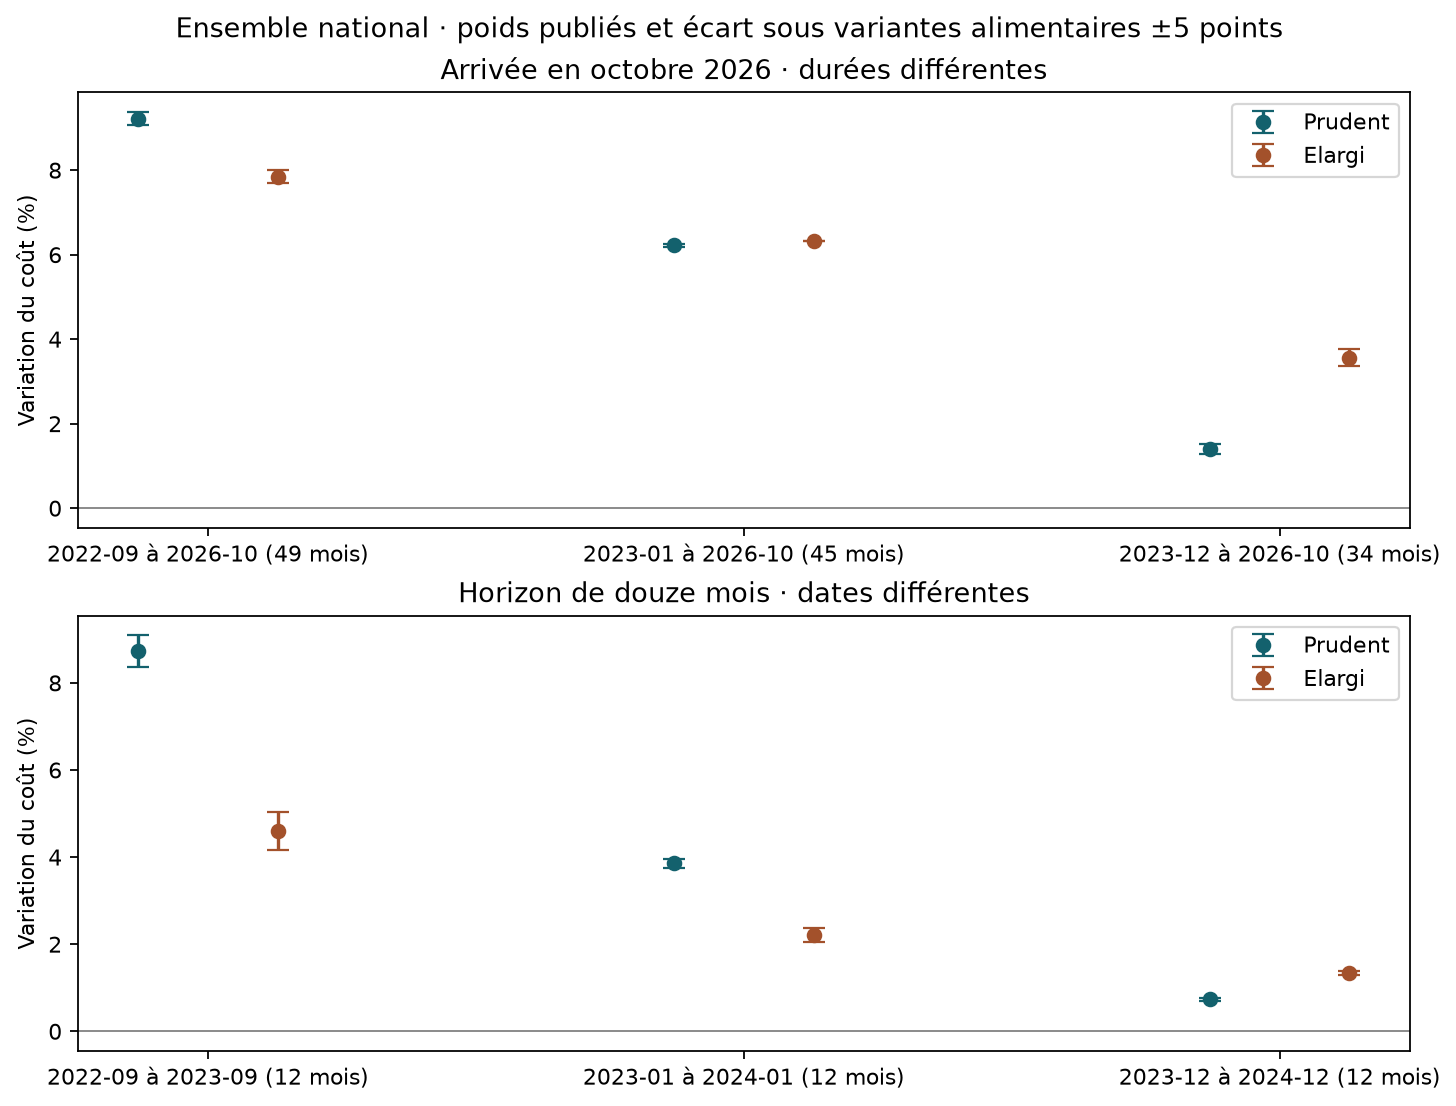

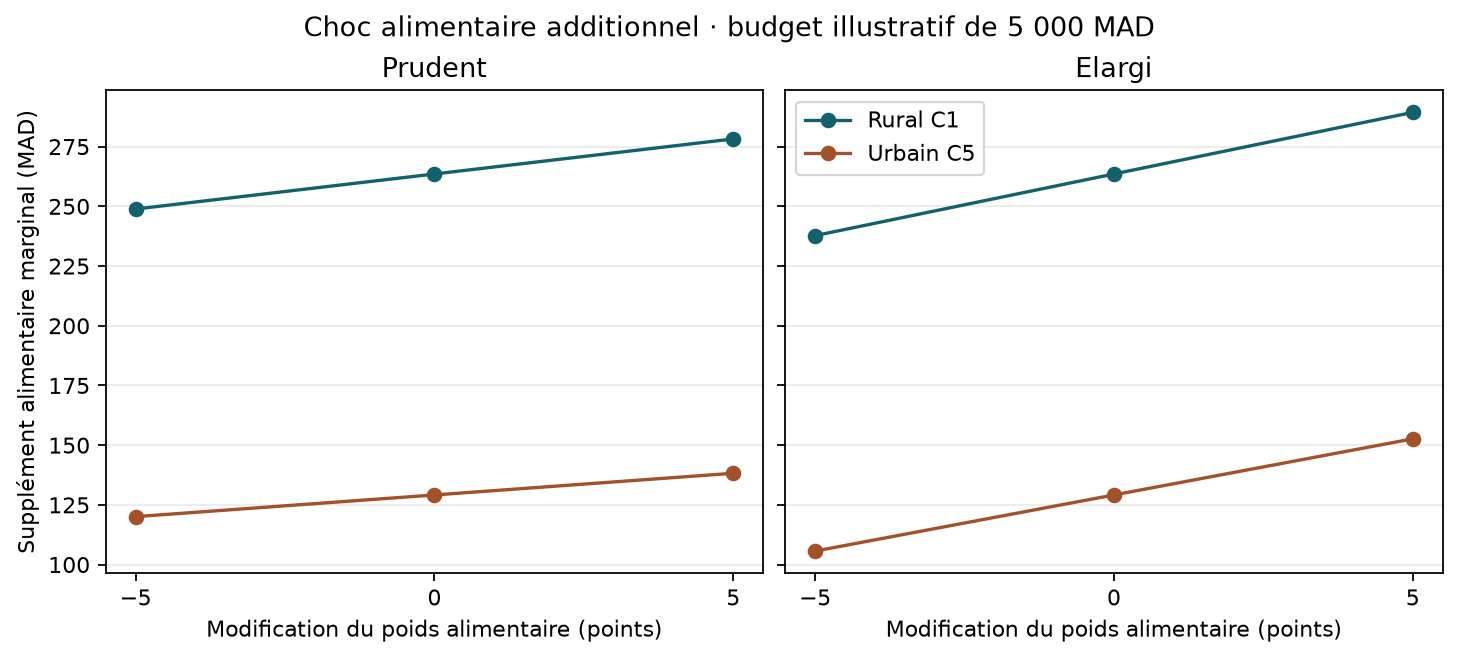

Contrôles réussis : catégories, couvertures, poids, périodes, chocs et relecture CSV.


In [5]:
destination.mkdir(exist_ok=True)

def enregistrer(figure, nom):
    chemin = destination / nom
    figure.savefig(chemin, dpi=160, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(chemin)))


figure, axes = plt.subplots(2, 1, figsize=(9, 6.8), layout="constrained")
for axe, comparaison, titre in zip(axes, ["fin_commune", "douze_mois"],
                                  ["Arrivée en octobre 2026 · durées différentes",
                                   "Horizon de douze mois · dates différentes"]):
    donnees = national.loc[national.comparaison.eq(comparaison)]
    for perimetre, couleur, decalage in [("prudent", "#13616d", -0.13), ("elargi", "#a3512b", 0.13)]:
        lignes = donnees.loc[donnees.perimetre.eq(perimetre)]
        grille = lignes.pivot(index="periode", columns="variante", values="variation_cout_sous_panier_pct")
        centre = grille["observee"].to_numpy()
        positions = np.arange(len(grille)) + decalage
        axe.errorbar(positions, centre,
                     yerr=[centre - grille.min(axis=1), grille.max(axis=1) - centre],
                     fmt="o", color=couleur, capsize=5, label=perimetre.capitalize())
    axe.set_xticks(np.arange(len(grille)), grille.index)
    axe.axhline(0, color="gray", linewidth=0.8)
    axe.set(title=titre, ylabel="Variation du coût (%)")
    axe.legend()
figure.suptitle("Ensemble national · poids publiés et écart sous variantes alimentaires ±5 points")
enregistrer(figure, "sensibilite_historique.png")

figure, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True, layout="constrained")
for axe, perimetre in zip(axes, perimetres):
    donnees = selection.loc[selection.perimetre.eq(perimetre)]
    for profil, couleur in [("Rural_C1", "#13616d"), ("Urbain_C5", "#a3512b")]:
        valeurs = donnees.loc[donnees.profil.eq(profil)].set_index("variante")
        ordre = ["alimentaire_moins_5_pts", "observee", "alimentaire_plus_5_pts"]
        axe.plot([-5, 0, 5], valeurs.loc[ordre, "supplement_alimentaire_marginal_mad"],
                 marker="o", label=profil.replace("_", " "), color=couleur)
    axe.set(title=perimetre.capitalize(), xlabel="Modification du poids alimentaire (points)")
    axe.set_xticks([-5, 0, 5])
    axe.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Supplément alimentaire marginal (MAD)")
axes[1].legend()
figure.suptitle("Choc alimentaire additionnel · budget illustratif de 5 000 MAD")
enregistrer(figure, "choc_alimentaire_rural_urbain.png")

# Vérifier les exports après écriture, avec la précision fixée pour le CSV.
for nom, table in [
    ("comparaisons_historiques.csv", historique),
    ("ponderations_alternatives.csv", ponderations),
    ("chocs_alimentaires.csv", chocs),
    ("comparaison_rural_c1_urbain_c5.csv", selection),
]:
    chemin = destination / nom
    table.to_csv(chemin, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d", float_format="%.8f")
    dates_csv = [col for col in ["reference", "arrivee"] if col in table]
    relecture = pd.read_csv(chemin, parse_dates=dates_csv)
    pd.testing.assert_frame_equal(relecture, table.reset_index(drop=True),
                                  check_dtype=False, rtol=0, atol=6e-9)
print("Contrôles réussis : catégories, couvertures, poids, périodes, chocs et relecture CSV.")

## 5. Discussion scientifique

La robustesse est évaluée dans les variantes effectivement testées. Une différence qui persiste sur ces fenêtres et pour ces pondérations peut dépendre de choix plus éloignés de ceux retenus ici. Les différences entre périmètres combinent un changement des catégories suivies et de leurs poids au sein du sous-panier. Les chocs ne permettent pas d’estimer un comportement de substitution. Les indices communs à collecte urbaine appliqués aux profils ruraux isolent un effet de composition budgétaire sous cette hypothèse, sans mesurer des prix ruraux propres. Les tables agrégées ne fournissent ni trajectoires de revenus comparables ni réponses de consommation par profil. L’évolution du pouvoir d’achat effectif reste hors du champ de l’analyse.

**Sensibilité des résultats historiques.** Pour l’ensemble national, avec les poids publiés et une durée commune de douze mois, le prudent augmente davantage que l’élargi dans les deux premières fenêtres. L’ordre s’inverse dans la fenêtre décembre 2023–décembre 2024 (0,73 % contre 1,34 %). Dans cette dernière fenêtre, relever le poids alimentaire de cinq points réduit les deux taux, à 0,70 % et 1,28 %. L’effet d’une pondération alimentaire accrue dépend donc des variations relatives des prix dans la fenêtre retenue.

**Sensibilité au choc combiné.** Dans l’élargi, le coût du sous-panier de Rural C1 augmente de 9,84 % à 10,89 % selon la variante, autour de 10,36 % avec les poids publiés. Le franchissement d’un repère de 10 % dépend ainsi de la pondération, même si le classement de Rural C1 et Urbain C5 pour le supplément alimentaire marginal est stable.


In [6]:
def fr(nombre):
    return f"{nombre:.2f}".replace(".", ",")


base = selection.loc[selection.variante.eq("observee")].set_index(["profil", "perimetre"])
for perimetre in perimetres:
    mesures = base.xs(perimetre, level="perimetre")["supplement_alimentaire_marginal_mad"]
    display(Markdown(
        f"**{perimetre.capitalize()}, poids publiés.** Le choc alimentaire ajoute "
        f"**{fr(mesures['Rural_C1'])} MAD** à la hausse uniforme pour Rural C1, "
        f"contre **{fr(mesures['Urbain_C5'])} MAD** pour Urbain C5."
    ))
ordre_choc = selection.pivot(index=["perimetre", "variante"], columns="profil",
                              values="supplement_alimentaire_marginal_mad")
ecarts = ordre_choc["Rural_C1"] - ordre_choc["Urbain_C5"]
# Tester aussi les variantes opposées pour les deux profils.
marges = selection.groupby(["perimetre", "profil"])["supplement_alimentaire_marginal_mad"].agg(["min", "max"])
ordre_toutes_paires = (marges.xs("Rural_C1", level="profil")["min"]
                       > marges.xs("Urbain_C5", level="profil")["max"]).all()
verdict = ("persiste même en opposant les variantes les plus défavorables au classement"
           if ordre_toutes_paires else "dépend de la variante lorsque les profils ont des poids modifiés différemment")
display(Markdown(
    f"**Résultat du choc.** À variante identique, Rural C1 dépasse Urbain C5 dans "
    f"{int(ecarts.gt(0).sum())} comparaisons sur {len(ecarts)}. L’ordre {verdict}."
))

couples = historique.pivot(index=["profil", "variante", "comparaison", "reference"],
                           columns="perimetre", values="variation_cout_sous_panier_pct")
superieur = couples["prudent"].gt(couples["elargi"])
for comparaison in ["fin_commune", "douze_mois"]:
    lus = superieur.xs(comparaison, level="comparaison")
    display(Markdown(
        f"**{comparaison.replace('_', ' ').capitalize()}.** La hausse du coût prudent "
        f"dépasse celle de l’élargi dans {int(lus.sum())} comparaisons appariées sur {len(lus)}. "
        "Chaque paire compare le même profil, la même variante et les mêmes dates."
    ))

**Prudent, poids publiés.** Le choc alimentaire ajoute **263,55 MAD** à la hausse uniforme pour Rural C1, contre **129,15 MAD** pour Urbain C5.

**Elargi, poids publiés.** Le choc alimentaire ajoute **263,55 MAD** à la hausse uniforme pour Rural C1, contre **129,15 MAD** pour Urbain C5.

**Résultat du choc.** À variante identique, Rural C1 dépasse Urbain C5 dans 6 comparaisons sur 6. L’ordre persiste même en opposant les variantes les plus défavorables au classement.

**Fin commune.** La hausse du coût prudent dépasse celle de l’élargi dans 57 comparaisons appariées sur 162. Chaque paire compare le même profil, la même variante et les mêmes dates.

**Douze mois.** La hausse du coût prudent dépasse celle de l’élargi dans 108 comparaisons appariées sur 162. Chaque paire compare le même profil, la même variante et les mêmes dates.